5. Every transformation and every selection is fitted on the training actors of each LOSO fold, and never on all 
videos. In this section C is fixed to the value chosen most often in 4.6; state in the report what this 
simplification may cost. The features are all those of Section 3.

C is fixed at 1, the value chosen in 16 of the 20 folds of 4.6, which used all the features of Section 3. This may cost us in two ways. First, the pipelines with PCA or feature selection feed the SVM a different input (fewer or transformed features), and C = 1 was not tuned for it, so these pipelines may be slightly underestimated relative to the baseline, which uses the C that was tuned for it. Second, the most frequent value was read off all the development actors, so the LOSO scores of this section are marginally optimistic.

Question 5.1 Apply principal component analysis (PCA) to the standardised features of all development videos, for 
exploration only. Plot the cumulative explained variance and report the number of components that explain 75 % and 95 % of the variance. Which measures dominate the first two components? Plot the videos on the first two components, coloured by emotion.

Initial total features:['M1_mean', 'M1_std', 'M1_range', 'M1_v', 'M1_E', 'M2_mean', 'M2_std', 'M2_range', 'M2_v', 'M2_E', 'M3_mean', 'M3_std', 'M3_range', 'M3_v', 'M3_E', 'M4_mean', 'M4_std', 'M4_range', 'M4_v', 'M4_E', 'M5_mean', 'M5_std', 'M5_range', 'M5_v', 'M5_E', 'M6_mean', 'M6_std', 'M6_range', 'M6_v', 'M6_E', 'M7_mean', 'M7_std', 'M7_range', 'M7_v', 'M7_E', 'M8_mean', 'M8_std', 'M8_range', 'M8_v', 'M8_E', 'M9_mean', 'M9_std', 'M9_range', 'M9_v', 'M9_E', 'M10_mean', 'M10_std', 'M10_range', 'M10_v', 'M10_E', 'M11_mean', 'M11_std', 'M11_range', 'M11_v', 'M11_E']
Cumulative Explained Variance: [0.35824443 0.48238188 0.55162382 0.602934   0.64529044 0.68383805
 0.71372853 0.74164394 0.76600584 0.78983118 0.8117431  0.83199225
 0.84833311 0.86278187 0.87671897 0.88943037 0.900921   0.91038139
 0.91932735 0.92710434 0.93437174 0.94047713 0.94629153 0.95153849
 0.95625645 0.9605816  0.96453213 0.96795517 0.97096216 0.97387124
 0.97646721 0.97894269 0.98105768 0.98303803 0.98474948 0.986

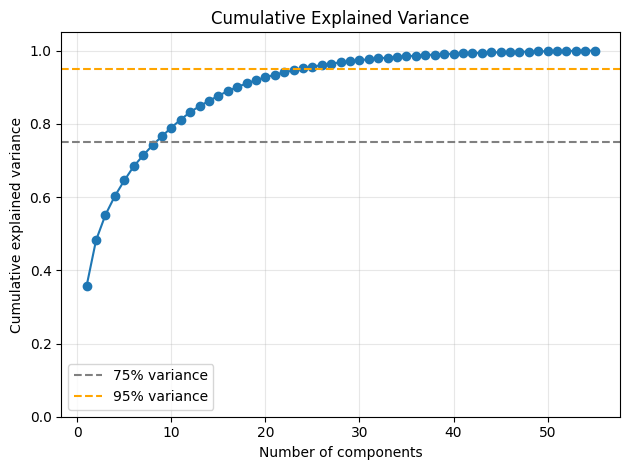

Number of components: 55
Number of components for 75% variance: 9
Number of components for 95% variance: 24

--- Dominant Measures for PC1 ---
measure
M1     0.151265
M2     0.148551
M8     0.148230
M10    0.148040
M3     0.147317
M7     0.147260
M9     0.108019
M6     0.098009
M11    0.085254
M4     0.082461
M5     0.067646
Name: PC1, dtype: float64

--- Dominant Measures for PC2 ---
measure
M4     0.220353
M5     0.213342
M1     0.152493
M9     0.127529
M11    0.117871
M6     0.112548
M10    0.096578
M2     0.089104
M3     0.063419
M7     0.061212
M8     0.020000
Name: PC2, dtype: float64


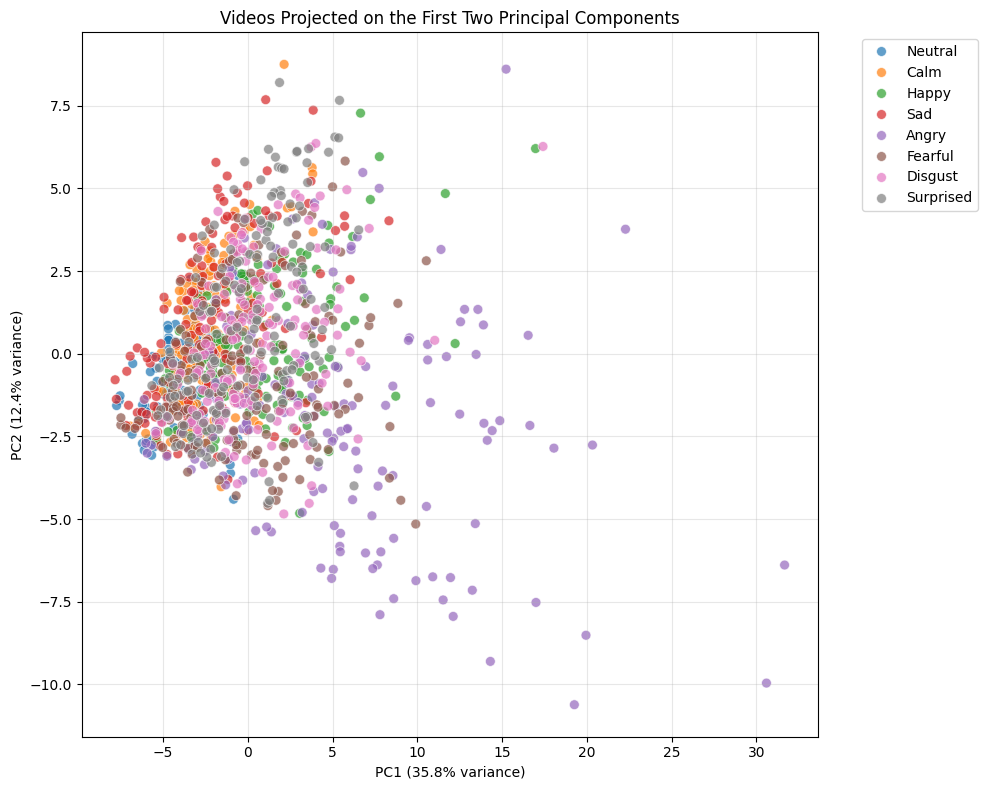

In [11]:
import numpy as np
from sklearn.decomposition import PCA
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

df_all = pd.read_parquet("new_3.2_video_measurements.gzip")
testIndex = pd.read_parquet("testIndex.gzip")
dev_data = df_all[
    ~df_all["video"].isin(testIndex["video"])
].copy()

# Extract actor ID from the video filename
dev_data["actor"] = (
    dev_data["video"]
    .str.replace(".csv", "", regex=False)
    .str.split("-")
    .str[-1]
)

feature_cols = [
    c for c in dev_data.select_dtypes(include="number").columns
    if c != "frame"
]
print(f"Initial total features:{feature_cols}")
X = StandardScaler().fit_transform(dev_data[feature_cols])

pca = PCA()
pca.fit(X)
cumulative_explained_variance = np.cumsum(pca.explained_variance_ratio_)
print(f"Cumulative Explained Variance: {cumulative_explained_variance}")

components = np.arange(1, pca.n_components_ + 1)
plt.plot(components, cumulative_explained_variance, marker="o")
plt.axhline(y=0.75, color="gray", linestyle="--", label="75% variance")
plt.axhline(y=0.95, color="orange", linestyle="--", label="95% variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("Cumulative Explained Variance")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Number of components: {pca.n_components_}")

import seaborn as sns

# 1. Report the number of components for 75% and 95% variance
n_comp_75 = np.argmax(cumulative_explained_variance >= 0.75) + 1
n_comp_95 = np.argmax(cumulative_explained_variance >= 0.95) + 1
print(f"Number of components for 75% variance: {n_comp_75}")
print(f"Number of components for 95% variance: {n_comp_95}")

# 2. Determine which measures dominate the first two components
feature_names = feature_cols
loadings_df = pd.DataFrame(
    pca.components_[:2, :], 
    columns=feature_names, 
    index=['PC1', 'PC2']
).T

# Add the measure group column
loadings_df['measure'] = [col.split('_')[0] if '_' in col else col for col in feature_names]

# Take absolute values only on the numeric PC columns, then group by measure
numeric_loadings = loadings_df[['PC1', 'PC2']].abs()
numeric_loadings['measure'] = loadings_df['measure']
measure_importance = numeric_loadings.groupby('measure').mean()

print("\n--- Dominant Measures for PC1 ---")
print(measure_importance['PC1'].sort_values(ascending=False))

print("\n--- Dominant Measures for PC2 ---")
print(measure_importance['PC2'].sort_values(ascending=False))

# 3. Plot the videos on the first two components, coloured by emotion
X_pca = pca.transform(X)
plot_df = pd.DataFrame(X_pca[:, :2], columns=['PC1', 'PC2'])
plot_df['emotion'] = dev_data['emotion'].values

plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=plot_df, 
    x='PC1', 
    y='PC2', 
    hue='emotion', 
    palette='tab10', 
    alpha=0.7, 
    s=50
)
plt.title("Videos Projected on the First Two Principal Components")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The number of principal components required to explain 75% of the variance is 9, while the number required to explain 95% is 24.
After the features were grouped up based on their measure, and their absolute PC1 and PC2 weights were averaged (mean), we found that the dominant measures for PC1 were, from most dominant to least, M1, M2,M8, M10, M3, M7, M9, M6, M11, M4 and M5, while the dominant measures for PC2 were M4, M5, M1, M9, M11, M6, M10, M2, M3, M7 and M8.

Question 5.2 Under LOSO, evaluate the pipelines StandardScaler → PCA → SVC keeping 75 % and 95 % of the 
variance. Compare with all the features. Does compressing the representation help the classifier? 
Why?

In [12]:

from sklearn.decomposition import PCA
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import pandas as pd

X = dev_data[feature_cols]
y = dev_data["emotion"]
groups = dev_data["actor"]

logo = LeaveOneGroupOut()

# Keep the specified proportion of variance in each training fold.
pca_variants = {
    "PCA 75% variance": 0.75,
    "PCA 95% variance": 0.95,
}

results_52 = {}

for name, variance in pca_variants.items():
    fold_accuracies = []
    fold_f1 = []
    fold_n_components = []

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=variance)),
        ("svc", SVC(C=1, kernel="rbf")),
    ])

    for train_idx, test_idx in logo.split(X, y, groups=groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)

        fold_accuracies.append(
            accuracy_score(y_test, y_pred)
        )
        fold_f1.append(
            f1_score(y_test, y_pred, average="macro")
        )
        fold_n_components.append(
            pipeline.named_steps["pca"].n_components_
        )

    results_52[name] = {
        "Mean accuracy": np.mean(fold_accuracies),
        "Std accuracy": np.std(fold_accuracies),
        "Mean macro F1": np.mean(fold_f1),
        "Std macro F1": np.std(fold_f1),
        "Mean components": np.mean(fold_n_components),
    }

    print(f"\n{name}")
    print(
        f"Accuracy: {np.mean(fold_accuracies):.3f} "
        f"± {np.std(fold_accuracies):.3f}"
    )
    print(
        f"Macro F1: {np.mean(fold_f1):.3f} "
        f"± {np.std(fold_f1):.3f}"
    )
    print(
        f"Mean number of components: "
        f"{np.mean(fold_n_components):.1f}"
    )

pca_results_df = pd.DataFrame(results_52).T
pca_results_df.round(3)



PCA 75% variance
Accuracy: 0.532 ± 0.111
Macro F1: 0.510 ± 0.115
Mean number of components: 9.0

PCA 95% variance
Accuracy: 0.577 ± 0.110
Macro F1: 0.550 ± 0.119
Mean number of components: 24.0


,Mean accuracy,Std accuracy,Mean macro F1,Std macro F1,Mean components
PCA 75% variance,0.532,0.111,0.51,0.115,9.0
PCA 95% variance,0.577,0.110,0.55,0.119,24.0


The difference between the mean accuracy of 75% variance and 95% is of just 0.045 while their standard deviations are 0.111 and 0.110. Since their standard deviation is larger than the difference in mean,the discrepancy between the performance of 75% and 95% variance is considered not statistically significant.

Since compressing the representation does not meaningfully hurt performance, it is preferred, as it reduces noise and risk of overfitting.

Question 5.3
Univariate selection: SelectKBest with the ANOVA F-statistic (f_classif) inside the pipeline, with K = 5, 10 and 15. Report the LOSO macro F1.

In [13]:
from sklearn.feature_selection import SelectKBest,f_classif
from sklearn.metrics import f1_score

X = dev_data[feature_cols]
y = dev_data["emotion"]
groups = dev_data["actor"]

logo = LeaveOneGroupOut()
k_dic = {"K=5" : 5,"K=10" : 10,"K=15" : 15}
results_53 = {}

for name, k in k_dic.items():
    pipeline = Pipeline(
            [
                ("scaler", StandardScaler()),
                ("select", SelectKBest(f_classif, k=k)),
                ("svc", SVC(C=1, kernel="rbf", random_state=42)),
            ]
        )

    fold_f1 = []
    for train_idx, test_idx in logo.split(X, y, groups=groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        
        # Fit ONLY on training actors, evaluate on left-out test actor
        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)
        fold_f1.append(f1_score(y_test, y_pred, average="macro"))
        
    results_53[name] = [np.mean(fold_f1), np.std(fold_f1)]
    
    print(f"LOSO MACRO F1 FOR {name}: {np.mean(fold_f1) * 100:.2f}% (± {np.std(fold_f1) * 100:.2f}%)\n")

# ==========================================
# 3. Summary Table
# ==========================================
df_results_53 = pd.DataFrame(
    results_53, index=["Mean Macro F1", "Std Dev"]
).T.style.format("{:.4f}")    

df_results_53
    

LOSO MACRO F1 FOR K=5: 35.95% (± 10.26%)

LOSO MACRO F1 FOR K=10: 41.61% (± 11.77%)

LOSO MACRO F1 FOR K=15: 45.03% (± 9.70%)



,Mean Macro F1,Std Dev
K=5,0.3595,0.1026
K=10,0.4161,0.1177
K=15,0.4503,0.0970


Question 5.4 
Minimum redundancy, maximum relevance (mRMR) [6]: select K = 5, 10 and 15 features with mrmr_classif from the mrmr_selection package (pip install mrmr_selection), on the training actors of each LOSO fold. With its default arguments, the package measures the relevance of a feature by its F-statistic and its redundancy by its mean absolute Pearson correlation with the features already selected, and selects at each step the feature that maximises the quotient of the two, a variant proposed for continuous features in [7]. The function is not a scikit-learn transformer: the selection is performed explicitly within each fold, or wrapped in a transformer. Compare with 5.3.

In [14]:
from mrmr import mrmr_classif

logo = LeaveOneGroupOut()
results_54 = {}
values_k = {"k = 5": 5, "k = 10":10, "k = 15":15}

for name, k in values_k.items():
    fold_f1 = []
    for train_idx, test_idx in logo.split(X, y, groups=groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        columns = mrmr_classif(X = X_train, y = y_train , K=k, show_progress= False)

        pipeline = Pipeline(
                    [
                        ("scaler", StandardScaler()),
                        ("svc", SVC(C=1, kernel="rbf", random_state=42)),
                    ]
                )

        pipeline.fit(X_train[columns], y_train)
        y_pred = pipeline.predict(X_test[columns])

        fold_f1.append(f1_score(y_test, y_pred, average="macro"))
    results_54[name] = [np.mean(fold_f1), np.std(fold_f1)]
    
    print(f"LOSO MACRO F1 FOR {name}: {np.mean(fold_f1) * 100:.2f}% (± {np.std(fold_f1) * 100:.2f}%)\n")

# ==========================================
# 3. Summary Table
# ==========================================
df_results_54 = pd.DataFrame(
    results_54, index=["Mean Macro F1", "Std Dev"]
).T.style.format("{:.4f}")    

df_results_54

#Compare with 5.3
df_53_54 = pd.DataFrame({
    "ANOVA (5.3)": {k: v[0] for k, v in results_53.items()},
    "mRMR (5.4)": {k: v[0] for k, v in results_54.items()},
})

df_53_54
    

        
        




LOSO MACRO F1 FOR k = 5: 39.79% (± 15.22%)

LOSO MACRO F1 FOR k = 10: 48.13% (± 11.75%)

LOSO MACRO F1 FOR k = 15: 48.62% (± 12.65%)



,ANOVA (5.3),mRMR (5.4)
K=5,0.359459,NaN
K=10,0.416108,NaN
K=15,0.450280,NaN
k = 5,NaN,0.397930
k = 10,NaN,0.481338
k = 15,NaN,0.486190


We can see that for all values ​​of k, mRMR obtains a better result than ANOVA. The difference between ANOVA and mRMR is most pronounced at k = 10, where the difference is (0.48 - 0.41 = 0.07). We can also observe that in this case, mRMR is more efficient, as it obtained a better result with 10 features (k=10 => 0.48) than ANOVA with 15 features (k=15 => 0.45).

Question 5.5
For K = 10, count how many times each feature is selected over the 20 folds, by the ANOVA selection and by mRMR, and group the counts by measure (M1 to M6, and the features of 3.2). Relate the differences to 3.4.

In [15]:
from collections import Counter

count_ANOVA = Counter()
count_mRMR = Counter()

for train_idx, test_idx in logo.split(X, y, groups=groups):
    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]

    skb = SelectKBest(f_classif, k=10).fit(X_train, y_train)
    count_ANOVA.update(X.columns[skb.get_support()])

    count_mRMR.update(mrmr_classif(X=X_train, y=y_train, K=10, show_progress=False))

count_geral = pd.DataFrame({"ANOVA": pd.Series(count_ANOVA), "mRMR": pd.Series(count_mRMR)})
print("===Number of folders selected the variable===")
print(count_geral)

print("group the counts by measure")
count_geral["measures"] = count_geral.index.str.split("_").str[0]
print(count_geral.groupby("measures")[["ANOVA", "mRMR"]].sum())

===Number of folders selected the variable===
          ANOVA  mRMR
M1_E        2.0   NaN
M1_mean    16.0  20.0
M1_std      NaN   6.0
M1_v       20.0   2.0
M2_E        1.0   1.0
M2_mean    20.0  20.0
M2_range    1.0   NaN
M2_v       20.0   4.0
M3_v       14.0   6.0
M4_mean     NaN   3.0
M4_range    NaN   5.0
M4_v        NaN   2.0
M5_mean    20.0  20.0
M5_v        NaN   2.0
M6_mean     1.0  20.0
M6_std      NaN   1.0
M7_E        1.0   NaN
M7_range   20.0   2.0
M7_std     18.0  20.0
M7_v       20.0  20.0
M8_mean    20.0  20.0
M8_range    1.0   1.0
M8_std      NaN   1.0
M8_v        5.0   NaN
M9_E        NaN   2.0
M9_mean     NaN  17.0
M9_v        NaN   5.0
group the counts by measure
          ANOVA  mRMR
measures             
M1         38.0  28.0
M2         42.0  25.0
M3         14.0   6.0
M4          0.0  10.0
M5         20.0  22.0
M6          1.0  21.0
M7         59.0  42.0
M8         26.0  22.0
M9          0.0  24.0


Question 5.6
Summarise in one table every configuration evaluated under LOSO: all the features, the 30 features of Tables 2 and 3 (4.8), PCA, ANOVA and mRMR with each K, with the number of features and the macro F1 (mean and standard deviation). Which pipeline would you deliver, and why? Is the score the only criterion?

In [16]:

import pandas as pd
import numpy as np

# Load the saved results from Q4.2 and Q4.8
results42 = pd.read_parquet("42_results.gzip")
results48 = pd.read_parquet("48_results.gzip")

summary_rows = []

# Helper to add a row to the summary table
def add_row(configuration, n_features, mean_f1, std_f1):
    summary_rows.append({
        "Configuration": configuration,
        "Number of features": n_features,
        "Mean macro F1": mean_f1,
        "Std macro F1": std_f1
    })

# 1. All 55 features: Q4.2, fixed default SVC parameters (C=1)
add_row(
    "All 55 features (Q4.2)",
    55,
    results42["macro_f1"].mean(),
    results42["macro_f1"].std(ddof=0)
)

# 2. Original 30 features: Q4.8
# Q4.8 uses nested C tuning, so keep this distinction in the label.
add_row(
    "Original 30 features (Q4.8, tuned C)",
    30,
    results48["outer_f1"].mean(),
    results48["outer_f1"].std(ddof=0)
)

# 3. PCA results from Q5.2
# Expects results_52 to contain mean/std macro F1 and mean components.
for name, result in results_52.items():
    add_row(
        name,
        round(result["Mean components"]),
        result["Mean macro F1"],
        result["Std macro F1"]
    )

# 4. ANOVA results from Q5.3
# results_53 format: {"K=5": [mean_f1, std_f1], ...}
for name, scores in results_53.items():
    k = int(name.split("=")[1].strip())
    add_row(
        f"ANOVA (K={k})",
        k,
        scores[0],
        scores[1]
    )

# 5. mRMR results from Q5.4
# results_54 format: {"k = 5": [mean_f1, std_f1], ...}
for name, scores in results_54.items():
    k = int(name.split("=")[1].strip())
    add_row(
        f"mRMR (K={k})",
        k,
        scores[0],
        scores[1]
    )

# Build and display the final table, best mean macro F1 first
summary_table = pd.DataFrame(summary_rows)
summary_table = (
    summary_table
    .sort_values("Mean macro F1", ascending=False)
    .reset_index(drop=True)
)

summary_table.round(3)


,Configuration,Number of features,Mean macro F1,Std macro F1
0,All 55 features (Q4.2),55,0.568,0.122
1,PCA 95% variance,24,0.550,0.119
2,"Original 30 features (Q4.8, tuned C)",30,0.526,0.131
3,PCA 75% variance,9,0.510,0.115
4,mRMR (K=15),15,0.486,0.126
5,mRMR (K=10),10,0.481,0.118
6,ANOVA (K=15),15,0.450,0.097
7,ANOVA (K=10),10,0.416,0.118
8,mRMR (K=5),5,0.398,0.152
9,ANOVA (K=5),5,0.359,0.103


I would choose PCA retaining 95% variance as a reasonable compromise between predictive performance and dimensionality reduction. It retains performance close to the full-feature baseline while reducing the number of input dimensions.

The score is not the only criterion. Model complexity, robustness to differences between actors, computational cost, and simplicity of deployment also matter.

Question 5.7 Fit the pipeline chosen in 5.6, with the value of C used in this section, on the 1200 development 
videos, and evaluate it once on the 240 videos of the test actors. Report accuracy and macro F1, the 
confusion matrix and the macro F1 of each test actor. From this point on, no decision of Sections 1 to 
5 is changed: a pipeline revised after seeing its test score no longer has an unbiased test score.

In [17]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# 1. Separate the development and test videos
df_all = pd.read_parquet("new_3.2_video_measurements.gzip")
testIndex = pd.read_parquet("testIndex.gzip")

test_data = df_all[df_all["video"].isin(testIndex["video"])].copy()
dev_data = df_all[~df_all["video"].isin(testIndex["video"])].copy()

# Extract actor IDs from the video filenames
dev_data["actor"] = (
    dev_data["video"].str.replace(".csv", "", regex=False)
    .str.split("-").str[-1]
)
test_data["actor"] = (
    test_data["video"].str.replace(".csv", "", regex=False)
    .str.split("-").str[-1]
)

# 2. Define features and labels
# Reuse the 55 feature columns established in Section 5
X_dev = dev_data[feature_cols]
y_dev = dev_data["emotion"]

X_test = test_data[feature_cols]
y_test = test_data["emotion"]

print("Development videos:", len(dev_data))
print("Test videos:", len(test_data))
print("Number of features:", len(feature_cols))
print("Test actors:", sorted(test_data["actor"].unique()))

# 3. Define and fit the selected pipeline on development data only
final_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95)),
    ("svc", SVC(C=1, kernel="rbf"))
])

final_pipeline.fit(X_dev, y_dev)

print(
    "Number of PCA components:",
    final_pipeline.named_steps["pca"].n_components_
)

# 4. Evaluate once on the held-out test set
y_pred = final_pipeline.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
test_macro_f1 = f1_score(y_test, y_pred, average="macro")

print(f"\nTest accuracy: {test_accuracy:.3f}")
print(f"Test macro F1: {test_macro_f1:.3f}")

# 5. Confusion matrix
labels = sorted(y_dev.unique())

cm = confusion_matrix(y_test, y_pred, labels=labels)
cm_df = pd.DataFrame(
    cm,
    index=[f"Actual {label}" for label in labels],
    columns=[f"Predicted {label}" for label in labels]
)

print("\nTest confusion matrix:")
display(cm_df)

# 6. Macro F1 for each held-out test actor
actor_results = []

for actor in sorted(test_data["actor"].unique()):
    mask = test_data["actor"].to_numpy() == actor

    actor_f1 = f1_score(
        y_test.iloc[np.flatnonzero(mask)],
        y_pred[mask],
        labels=labels,
        average="macro",
        zero_division=0
    )

    actor_results.append({
        "Actor": actor,
        "Macro F1": actor_f1
    })

actor_results_df = pd.DataFrame(actor_results)
print("\nMacro F1 by test actor:")
display(actor_results_df.round(3))

Development videos: 1200
Test videos: 240
Number of features: 55
Test actors: ['01', '16', '17', '24']
Number of PCA components: 24

Test accuracy: 0.562
Test macro F1: 0.540

Test confusion matrix:


,Predicted Angry,Predicted Calm,Predicted Disgust,Predicted Fearful,Predicted Happy,Predicted Neutral,Predicted Sad,Predicted Surprised
Actual Angry,25,1,0,2,0,0,4,0
Actual Calm,0,21,0,0,4,0,7,0
Actual Disgust,9,0,18,2,0,0,2,1
Actual Fearful,6,0,0,22,0,0,4,0
Actual Happy,0,6,1,0,22,0,0,3
Actual Neutral,0,2,0,1,0,7,5,1
Actual Sad,5,3,2,2,0,2,18,0
Actual Surprised,7,2,6,7,2,1,5,2



Macro F1 by test actor:


,Actor,Macro F1
0,01,0.447
1,16,0.546
2,17,0.633
3,24,0.428


Question 5.8 Compare the test score with the LOSO estimate of the same pipeline in 5.6. Which of the two is an 
unbiased estimate of the performance of the pipeline delivered, and why? From the distribution of 
the macro F1 over actors in 4.2, estimate how much the mean over four actors would vary from one 
choice of test actors to another. Is the difference between the two scores larger than that variation?

The PCA pipeline retaining 95% of the variance achieved a mean macro F1 of 0.550 under LOSO cross-validation in Section 5.6 and a macro F1 of 0.540 on the test actors in Section 5.7. The absolute difference between the scores is 0.010.

Both protocols evaluate generalisation to unseen actors, since each LOSO fold holds out one actor from training. However, the test score provides the more appropriate unbiased estimate of the performance of the final selected pipeline. The four test actors were kept separate from model development and pipeline selection, and the test set was evaluated only once. In contrast, the pipeline was selected after comparing configurations using the LOSO results, which can make its cross-validation score somewhat optimistic.

The macro F1 standard deviation across development actors in Section 4.2 was 0.122. Using this as an estimate of actor-to-actor variability, the standard error of the mean for four randomly selected actors is approximately (0.122/√4=0.061). This provides a rough indication of how much the average score might vary with the choice of four test actors. The observed difference of 0.010 is smaller than this estimate, suggesting that it can reasonably be explained by variation between actors rather than indicating a substantial difference in performance.